AIR QUALITY PREDICTION SYSTEM

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBRegressor
from xgboost import XGBClassifier

import joblib

In [3]:
air = pd.read_csv("C:\Environment/data/raw/Beijing Multisite air Quality data.csv")

In [4]:
air.head()

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [5]:
air.shape

(420768, 17)

In [6]:
air.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 17 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   year     420768 non-null  int64  
 1   month    420768 non-null  int64  
 2   day      420768 non-null  int64  
 3   hour     420768 non-null  int64  
 4   PM2.5    412029 non-null  float64
 5   PM10     414319 non-null  float64
 6   SO2      411747 non-null  float64
 7   NO2      408652 non-null  float64
 8   CO       400067 non-null  float64
 9   O3       407491 non-null  float64
 10  TEMP     420370 non-null  float64
 11  PRES     420375 non-null  float64
 12  DEWP     420365 non-null  float64
 13  RAIN     420378 non-null  float64
 14  wd       418946 non-null  object 
 15  WSPM     420450 non-null  float64
 16  station  420768 non-null  object 
dtypes: float64(11), int64(4), object(2)
memory usage: 54.6+ MB


In [7]:
air.describe()

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


In [8]:
air.tail()

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
420763,2017,2,28,19,11.0,32.0,3.0,24.0,400.0,72.0,12.5,1013.5,-16.2,0.0,NW,2.4,Wanshouxigong
420764,2017,2,28,20,13.0,32.0,3.0,41.0,500.0,50.0,11.6,1013.6,-15.1,0.0,WNW,0.9,Wanshouxigong
420765,2017,2,28,21,14.0,28.0,4.0,38.0,500.0,54.0,10.8,1014.2,-13.3,0.0,NW,1.1,Wanshouxigong
420766,2017,2,28,22,12.0,23.0,4.0,30.0,400.0,59.0,10.5,1014.4,-12.9,0.0,NNW,1.2,Wanshouxigong
420767,2017,2,28,23,13.0,19.0,4.0,38.0,600.0,49.0,8.6,1014.1,-15.9,0.0,NNE,1.3,Wanshouxigong


In [9]:
air.sample(5)

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
243879,2016,12,25,15,123.0,130.0,37.0,83.0,1700.0,2.0,1.1,1017.4,-6.9,0.0,ESE,1.0,Huairou
292862,2014,7,28,14,117.0,117.0,18.0,17.0,900.0,241.0,35.3,999.0,17.1,0.0,SW,3.8,Shunyi
22716,2015,10,3,12,27.0,75.0,7.0,48.0,900.0,62.0,22.4,1017.2,6.6,0.0,SSW,2.8,Aotizhongxin
249460,2013,8,15,4,81.0,71.0,4.0,36.0,1000.0,42.0,26.7,998.9,25.5,0.0,E,0.8,Nongzhanguan
59508,2015,12,14,12,125.0,125.0,23.0,75.0,2000.0,18.0,4.6,1013.3,-1.2,0.0,W,1.8,Changping


In [10]:
missing = air.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

CO       20701
O3       13277
NO2      12116
SO2       9021
PM2.5     8739
PM10      6449
wd        1822
DEWP       403
TEMP       398
PRES       393
RAIN       390
WSPM       318
dtype: int64

In [11]:
missing_percent = (air.isnull().sum() / len(air)) * 100

missing_percent[missing_percent > 0].sort_values(ascending=False)

CO       4.919813
O3       3.155421
NO2      2.879497
SO2      2.143937
PM2.5    2.076916
PM10     1.532674
wd       0.433018
DEWP     0.095777
TEMP     0.094589
PRES     0.093401
RAIN     0.092688
WSPM     0.075576
dtype: float64

In [12]:
air.duplicated().sum()

np.int64(0)

In [13]:
air = air.drop_duplicates()

In [14]:
air.columns

Index(['year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO',
       'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station'],
      dtype='object')

In [15]:
weather_cols = [
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
]

for col in weather_cols:
    air[col] = air[col].fillna(air[col].median())

In [16]:
pollutants = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3"
]

air[pollutants] = air[pollutants].interpolate()

In [17]:
air = air.dropna()

In [18]:
air.info()

<class 'pandas.core.frame.DataFrame'>
Index: 418946 entries, 0 to 420767
Data columns (total 17 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   year     418946 non-null  int64  
 1   month    418946 non-null  int64  
 2   day      418946 non-null  int64  
 3   hour     418946 non-null  int64  
 4   PM2.5    418946 non-null  float64
 5   PM10     418946 non-null  float64
 6   SO2      418946 non-null  float64
 7   NO2      418946 non-null  float64
 8   CO       418946 non-null  float64
 9   O3       418946 non-null  float64
 10  TEMP     418946 non-null  float64
 11  PRES     418946 non-null  float64
 12  DEWP     418946 non-null  float64
 13  RAIN     418946 non-null  float64
 14  wd       418946 non-null  object 
 15  WSPM     418946 non-null  float64
 16  station  418946 non-null  object 
dtypes: float64(11), int64(4), object(2)
memory usage: 57.5+ MB


In [19]:
air["datetime"] = pd.to_datetime(
    air[["year","month","day","hour"]]
)

In [20]:
air["day_of_week"] = air["datetime"].dt.dayofweek
air["month_num"] = air["datetime"].dt.month
air["season"] = ((air["month_num"] % 12 + 3) // 3)

In [21]:
air.columns

Index(['year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO',
       'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station',
       'datetime', 'day_of_week', 'month_num', 'season'],
      dtype='object')

In [22]:
drop_cols = [
    "station",
    "datetime"
]

air = air.drop(columns=drop_cols)

In [23]:
air["wd"].unique()

array(['NNW', 'N', 'NW', 'NNE', 'ENE', 'E', 'NE', 'W', 'SSW', 'WSW', 'SE',
       'WNW', 'SSE', 'ESE', 'S', 'SW'], dtype=object)

In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

air["wd"] = le.fit_transform(air["wd"])

In [25]:
air.isnull().sum()

year           0
month          0
day            0
hour           0
PM2.5          0
PM10           0
SO2            0
NO2            0
CO             0
O3             0
TEMP           0
PRES           0
DEWP           0
RAIN           0
wd             0
WSPM           0
day_of_week    0
month_num      0
season         0
dtype: int64

In [26]:
air.shape

(418946, 19)

In [27]:
air.dtypes

year             int64
month            int64
day              int64
hour             int64
PM2.5          float64
PM10           float64
SO2            float64
NO2            float64
CO             float64
O3             float64
TEMP           float64
PRES           float64
DEWP           float64
RAIN           float64
wd               int64
WSPM           float64
day_of_week      int32
month_num        int32
season           int32
dtype: object

In [28]:
air.to_csv("../data/processed/air_cleaned.csv", index=False)

In [29]:
features = [

    "SO2",

    "NO2",

    "CO",

    "O3",

    "TEMP",

    "PRES",

    "DEWP",

    "RAIN",

    "wd",

    "WSPM"

]

In [30]:
X = air[features]

y = air["PM2.5"]

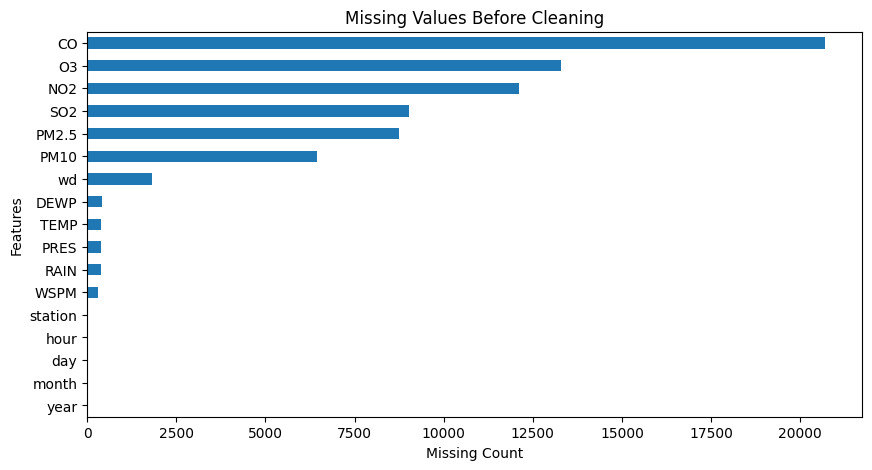

In [31]:
plt.figure(figsize=(10,5))

missing.sort_values().plot(kind="barh")

plt.title("Missing Values Before Cleaning")
plt.xlabel("Missing Count")
plt.ylabel("Features")

plt.show()

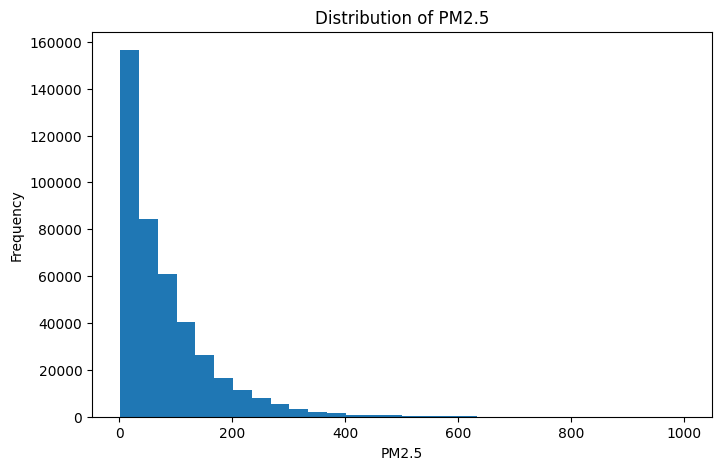

In [32]:
plt.figure(figsize=(8,5))

plt.hist(air["PM2.5"], bins=30)

plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5")
plt.ylabel("Frequency")

plt.show()

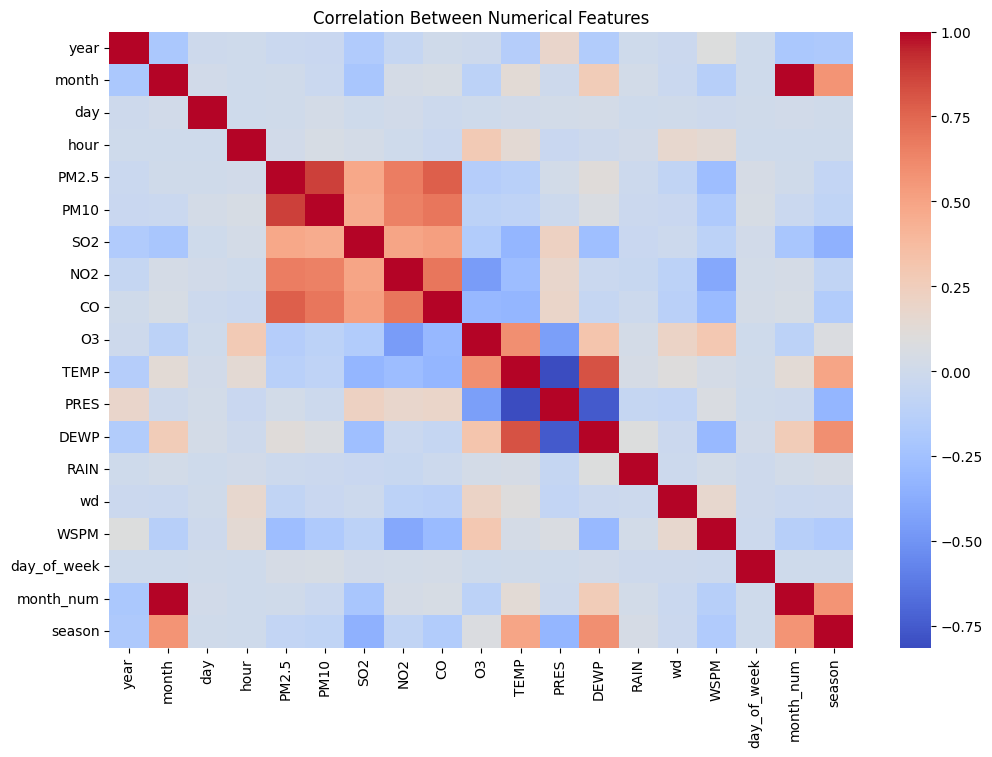

In [33]:
import seaborn as sns

plt.figure(figsize=(12,8))

sns.heatmap(
    air.corr(numeric_only=True),
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Between Numerical Features")

plt.show()

In [34]:
print("Features used for training:\n")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Features used for training:

['SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM']

Target Variable:
PM2.5


In [35]:
correlation = air.corr(numeric_only=True)

pm25_corr = correlation["PM2.5"].sort_values(ascending=False)

print(pm25_corr)

PM2.5          1.000000
PM10           0.878974
CO             0.780049
NO2            0.664445
SO2            0.478847
DEWP           0.113459
day_of_week    0.041487
PRES           0.019596
hour           0.010296
month          0.006246
month_num      0.006246
day            0.005577
RAIN          -0.014375
year          -0.027444
season        -0.073024
wd            -0.078365
TEMP          -0.131200
O3            -0.149061
WSPM          -0.271340
Name: PM2.5, dtype: float64


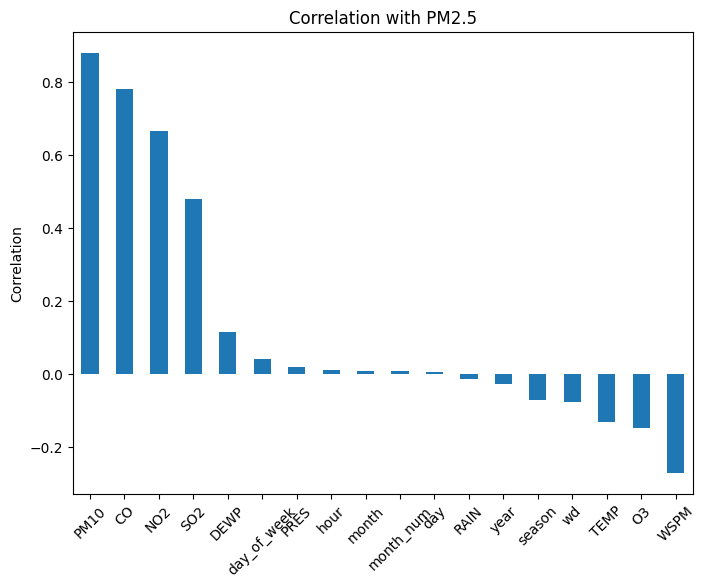

In [36]:
plt.figure(figsize=(8,6))

pm25_corr.drop("PM2.5").plot(kind="bar")

plt.title("Correlation with PM2.5")
plt.ylabel("Correlation")
plt.xticks(rotation=45)

plt.show()

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data :", X_train.shape)
print("Testing Data  :", X_test.shape) 

Training Data : (335156, 10)
Testing Data  : (83790, 10)


In [38]:
model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

model.fit(X_train, y_train) 

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [39]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[ 66.84744  212.1837   126.8362    56.26779   32.16791  102.24763
  95.35604   36.938755  39.748665 101.93414 ]


In [40]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae,2))
print("RMSE:", round(rmse,2))
print("R²  :", round(r2,4)) 

MAE : 22.89
RMSE: 35.62
R²  : 0.8071


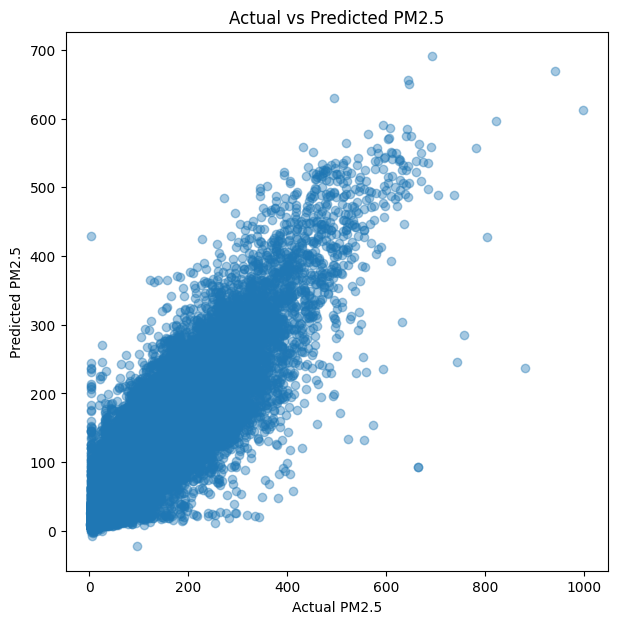

In [41]:
plt.figure(figsize=(7,7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")

plt.title("Actual vs Predicted PM2.5")

plt.show()

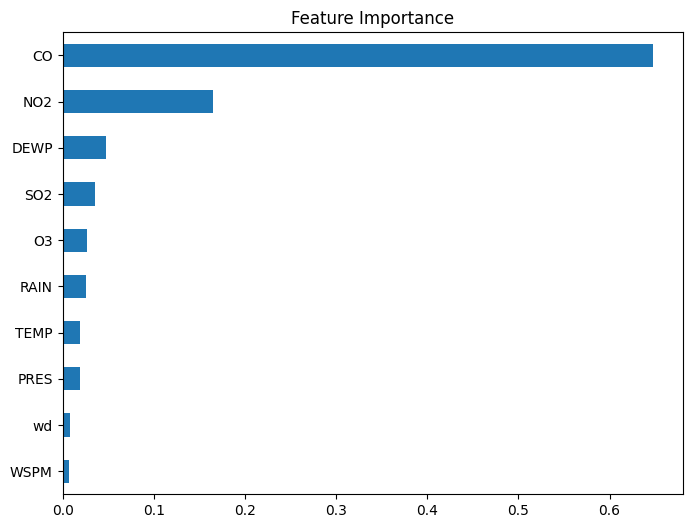

In [42]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values()

importance.plot(
    kind="barh",
    figsize=(8,6)
)

plt.title("Feature Importance")

plt.show()

In [43]:
joblib.dump(model, "../models/air_model.pkl")
joblib.dump(le, "../models/wd_encoder.pkl")

['../models/wd_encoder.pkl']